# 1. Import Libraries

In [1]:
import os
import random
import shutil
import numpy as np
import pandas as pd
import zipfile


import matplotlib.pyplot as plt


from PIL import Image


import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay



# 2. Load Dataset

In [2]:
pip install -q kagglehub

In [3]:
import kagglehub

In [4]:
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)

print("Dataset Path:")
print(dataset_path)

100%|██████████| 306M/306M [00:17<00:00, 18.0MB/s]

Extracting files...


Dataset Path:
/root/.cache/kagglehub/datasets/drgfreeman/rockpaperscissors/versions/2


In [5]:
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    {file}")

2/
    README_rpc-cv-images.txt
    rock/
        RpCSMPJ0LhFPYksZ.png
        bqpOIN5gUl0r6vIS.png
        WB7EanJC16YLgogF.png
        UCZq5Q5ovMiGJLwX.png
        H97IYAhAPk2kHnsI.png
    paper/
        eCZWzeGkpX6rdizo.png
        CnRjJejRPD3QmYTl.png
        SsvKZDW23vRQMUtA.png
        U2InMVDH10R24eOb.png
        V7gDBwuUctk8myTw.png
    rps-cv-images/
        README_rpc-cv-images.txt
        rock/
            RpCSMPJ0LhFPYksZ.png
            bqpOIN5gUl0r6vIS.png
            WB7EanJC16YLgogF.png
            UCZq5Q5ovMiGJLwX.png
            H97IYAhAPk2kHnsI.png
        paper/
            eCZWzeGkpX6rdizo.png
            CnRjJejRPD3QmYTl.png
            SsvKZDW23vRQMUtA.png
            U2InMVDH10R24eOb.png
            V7gDBwuUctk8myTw.png
        scissors/
            sC3hanWBPaeGV4xg.png
            xAnfzBYnsnuru9Nf.png
            JjS0KakWxwXmg5Wi.png
            i5CZnAPMNTZtM13A.png
            2ufDQYIqKG1xRG7y.png
    scissors/
        sC3hanWBPaeGV4xg.png
        xAnfzBYnsnur

In [6]:
data_dir = None

for root, dirs, files in os.walk(dataset_path):

    if all(folder in dirs for folder in ["rock", "paper", "scissors"]):
        data_dir = root
        break

print("Main Dataset Directory:")
print(data_dir)

Main Dataset Directory:
/root/.cache/kagglehub/datasets/drgfreeman/rockpaperscissors/versions/2


In [7]:
if data_dir is None:
    raise ValueError("Folder rock, paper, dan scissors tidak ditemukan.")

print(os.listdir(data_dir))

['rock', 'README_rpc-cv-images.txt', 'paper', 'rps-cv-images', 'scissors']


In [8]:
!wget -q https://www.kaggle.com/api/v1/datasets/download/drgfreeman/rockpaperscissors -O rockpaperscissors.zip

In [9]:
with zipfile.ZipFile("rockpaperscissors.zip", "r") as zip_ref:
    zip_ref.extractall("/content/rockpaperscissors")

print("Dataset berhasil diekstrak.")

Dataset berhasil diekstrak.


In [10]:
print(os.listdir("/content/rockpaperscissors"))

['rock', 'README_rpc-cv-images.txt', 'paper', 'rps-cv-images', 'scissors']


In [11]:
dataset_path = "/content/rockpaperscissors"

classes = ["rock", "paper", "scissors"]

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print(f"{class_name}: {len(files)} images")

rock: 726 images
paper: 712 images
scissors: 750 images


# 3. Exploratory Data Analysis

### Define Class

In [12]:
class_name = ["paper", "rock", "scissors"]

print("Classes:", class_name)
print("Number of Classes:", len(class_name))

Classes: ['paper', 'rock', 'scissors']
Number of Classes: 3


### Images Count

In [13]:
image_counts = {}

for class_name in class_name:
    class_path = os.path.join(data_dir, class_name)
    images = {
        file for file in os.listdir(class_path)
        if file.endswith(".png")
    }
    image_counts[class_name] = len(os.listdir(class_path))
image_counts




{'paper': 712, 'rock': 726, 'scissors': 750}

### Change to Dataframe

In [14]:
df_counts = pd.DataFrame({
    "Class": image_counts.keys(),
    "Number of Images": image_counts.values()
})
df_counts

,Class,Number of Images
0,paper,712
1,rock,726
2,scissors,750


### Distribution of Data

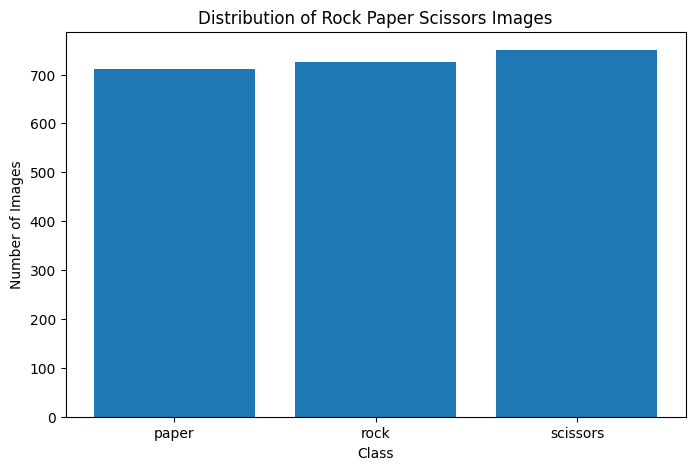

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_counts["Class"],
    df_counts["Number of Images"]
)

plt.title("Distribution of Rock Paper Scissors Images")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

Based on the distribution, the dataset can be considered **balanced**. Balanced data is essential to prevent the model from being biased toward classes with more samples.

### Images Characteristic

In [16]:

print(os.listdir("/content/rockpaperscissors"))

['rock', 'README_rpc-cv-images.txt', 'paper', 'rps-cv-images', 'scissors']


In [17]:
dataset_path = "/content/rockpaperscissors"
classes = ["rock", "paper", "scissors"]

image_info = []

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    for file_name in os.listdir(class_path):
        if file_name.lower().endswith((".png", ".jpg", ".jpeg")):
            file_path = os.path.join(class_path, file_name)

            with Image.open(file_path) as img:
                width, height = img.size

                image_info.append({
                    "class": class_name,
                    "filename": file_name,
                    "width": width,
                    "height": height,
                    "mode": img.mode,
                    "format": img.format
                })

df_image_info = pd.DataFrame(image_info)

df_image_info.head()

df_image_info = pd.DataFrame(image_info)

df_image_info.head()

,class,filename,width,height,mode,format
0,rock,RpCSMPJ0LhFPYksZ.png,300,200,RGB,PNG
1,rock,bqpOIN5gUl0r6vIS.png,300,200,RGB,PNG
2,rock,WB7EanJC16YLgogF.png,300,200,RGB,PNG
3,rock,UCZq5Q5ovMiGJLwX.png,300,200,RGB,PNG
4,rock,H97IYAhAPk2kHnsI.png,300,200,RGB,PNG


In [18]:
print("Total Images:", len(df_image_info))

print("\nImages per Class:")
print(df_image_info["class"].value_counts())

print("\nImage Formats:")
print(df_image_info["format"].value_counts())

print("\nColor Modes:")
print(df_image_info["mode"].value_counts())

print("\nImage Size Statistics:")
display(df_image_info[["width", "height"]].describe())

Total Images: 2188

Images per Class:
class
scissors    750
rock        726
paper       712
Name: count, dtype: int64

Image Formats:
format
PNG    2188
Name: count, dtype: int64

Color Modes:
mode
RGB    2188
Name: count, dtype: int64

Image Size Statistics:


,width,height
count,2188.0,2188.0
mean,300.0,200.0
std,0.0,0.0
min,300.0,200.0
25%,300.0,200.0
50%,300.0,200.0
75%,300.0,200.0
max,300.0,200.0


In [19]:
image_sizes = (
    df_image_info
    .groupby(["width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

image_sizes

,width,height,count
0,300,200,2188


In [20]:
df_image_info.groupby("class").agg(
    total_images=("filename", "count"),
    min_width=("width", "min"),
    max_width=("width", "max"),
    min_height=("height", "min"),
    max_height=("height", "max")
)

,total_images,min_width,max_width,min_height,max_height
class,,,,,
paper,712,300,300,200,200
rock,726,300,300,200,200
scissors,750,300,300,200,200


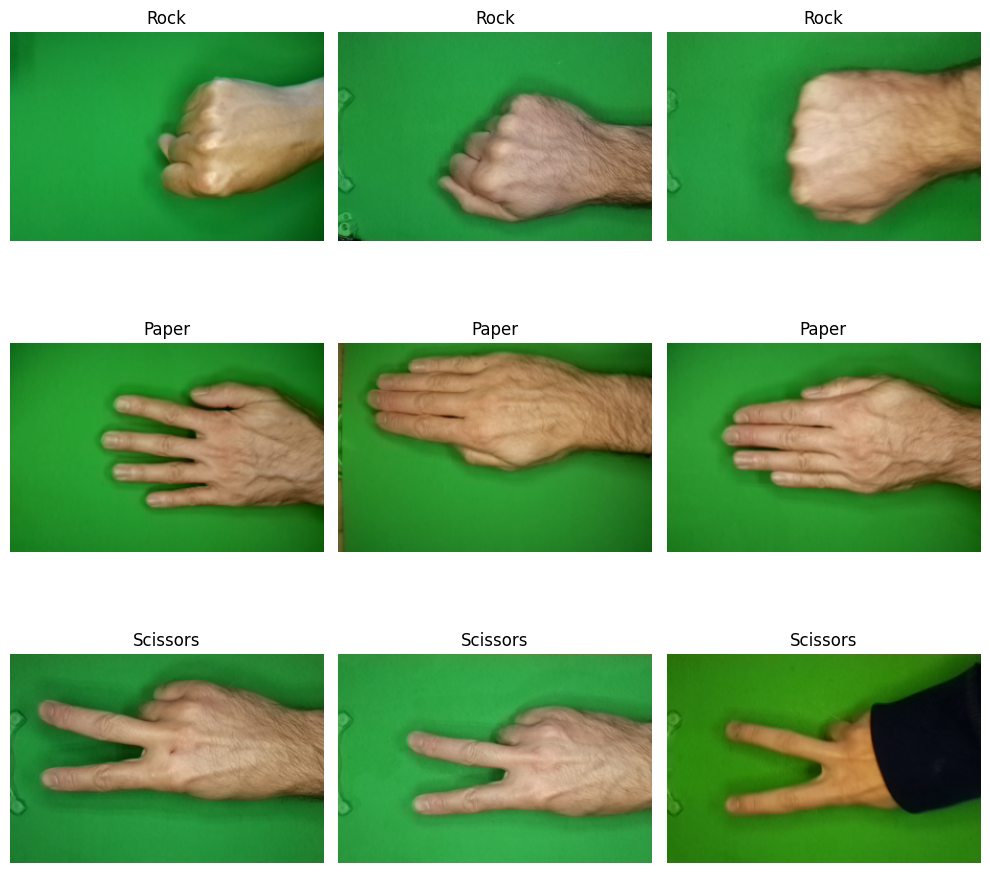

In [21]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for row, class_name in enumerate(classes):
    class_path = os.path.join(dataset_path, class_name)

    files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    selected_files = random.sample(files, 3)

    for col, file_name in enumerate(selected_files):
        img_path = os.path.join(class_path, file_name)
        img = Image.open(img_path)

        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name.capitalize())
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

- The dataset consists of 2,188 images divided into three classes.
- All images are in PNG format.
- All images use the RGB color mode.
- All images have the same dimensions, format, and color mode.
- Class imbalance handling is not required because the dataset is balanced.

# 4. Train , Test, and Validation Split

In [22]:
data_dir = "/content/rockpaperscissors"
split_dir = "/content/rps_split"
class_name = ["paper", "rock", "scissors"]

if os.path.exists(split_dir):
    shutil.rmtree(split_dir)

for split in ["train", "validation", "test"]:
    for cls in class_name:
        os.makedirs(
            os.path.join(split_dir, split, cls),
            exist_ok=True
        )

print("Split folders created.")

Split folders created.


In [23]:
for split in ["train", "validation", "test"]:
    for cls in class_name:
        folder = os.path.join(split_dir, split, cls)
        print(folder, "->", os.path.exists(folder))

/content/rps_split/train/paper -> True
/content/rps_split/train/rock -> True
/content/rps_split/train/scissors -> True
/content/rps_split/validation/paper -> True
/content/rps_split/validation/rock -> True
/content/rps_split/validation/scissors -> True
/content/rps_split/test/paper -> True
/content/rps_split/test/rock -> True
/content/rps_split/test/scissors -> True


In [24]:
random.seed(42)

for cls in class_name:

    source_dir = os.path.join(data_dir, cls)

    files = [
        file for file in os.listdir(source_dir)
        if file.lower().endswith(".png")
    ]

    random.shuffle(files)

    total = len(files)

    train_end = int(0.70 * total)
    val_end = int(0.85 * total)

    train_files = files[:train_end]
    val_files = files[train_end:val_end]
    test_files = files[val_end:]

    for file in train_files:
        shutil.copy(
            os.path.join(source_dir, file),
            os.path.join(split_dir, "train", cls, file)
        )

    for file in val_files:
        shutil.copy(
            os.path.join(source_dir, file),
            os.path.join(split_dir, "validation", cls, file)
        )

    for file in test_files:
        shutil.copy(
            os.path.join(source_dir, file),
            os.path.join(split_dir, "test", cls, file)
        )

    print(
        f"{cls}: "
        f"Train={len(train_files)}, "
        f"Validation={len(val_files)}, "
        f"Test={len(test_files)}"
    )

paper: Train=498, Validation=107, Test=107
rock: Train=508, Validation=109, Test=109
scissors: Train=525, Validation=112, Test=113


In [25]:
for split in ["train", "validation", "test"]:

    print(f"\n{split.upper()}")

    total_split = 0

    for cls in class_name:

        folder = os.path.join(split_dir, split, cls)

        total_images = len([
            file for file in os.listdir(folder)
            if file.lower().endswith(".png")
        ])

        total_split += total_images

        print(f"{cls}: {total_images}")

    print(f"Total {split}: {total_split}")


TRAIN
paper: 498
rock: 508
scissors: 525
Total train: 1531

VALIDATION
paper: 107
rock: 109
scissors: 112
Total validation: 328

TEST
paper: 107
rock: 109
scissors: 113
Total test: 329


In [26]:
train_dir = os.path.join(split_dir, "train")
val_dir = os.path.join(split_dir, "validation")
test_dir = os.path.join(split_dir, "test")

print("Train:", train_dir)
print("Validation:", val_dir)
print("Test:", test_dir)

Train: /content/rps_split/train
Validation: /content/rps_split/validation
Test: /content/rps_split/test


Define directories to simplify the code.

# 5. Image Preprocessing & Augmentation

In [27]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_datagen = ImageDataGenerator(
    rescale=1./255
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

- Since the images use the RGB color mode, pixel values are normalized using 1./255 to scale them from 0–255 to 0–1, making them more suitable for Computer Vision models.
- Data augmentation is only applied to the training data, as the validation and test datasets are used to evaluate the model's performance on original, unmodified data.
- Data augmentation techniques include horizontal flipping, height and width shifting, and zooming to increase data diversity and improve model generalization.


### Create Image Generator

In [28]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

validation_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 1531 images belonging to 3 classes.
Found 328 images belonging to 3 classes.
Found 329 images belonging to 3 classes.


In [29]:
print("Class Indices:")
print(train_generator.class_indices)

Class Indices:
{'paper': 0, 'rock': 1, 'scissors': 2}


**Class Map:**
0 = Paper
1 = Rock
2 = Scissors

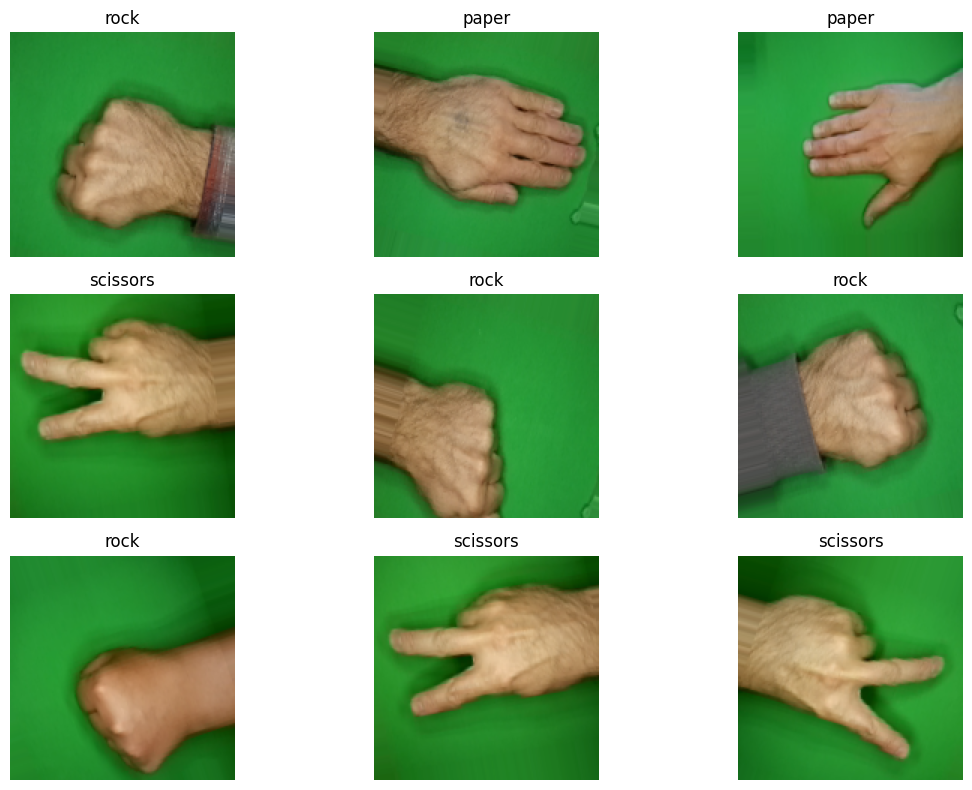

In [30]:
images, labels = next(train_generator)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i])

    label_index = np.argmax(labels[i])
    label_name = list(train_generator.class_indices.keys())[label_index]

    plt.title(label_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

This visualization shows the results of data augmentation. The images appear slightly rotated, shifted, or zoomed in.

# 6. Modeling 1

### Definition Model 1

In [49]:
tf.random.set_seed(42)

model_1 = Sequential([

    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(150, 150, 3)
    ),
    MaxPooling2D(2, 2),

    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D(2, 2),

    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D(2, 2),

    GlobalAveragePooling2D(),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.3),

    Dense(
        3,
        activation="softmax"
    )
])

model_1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

### Compile Model 1

In [50]:
model_1.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

### Callback Model 1

In [51]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

### Train Model 1

In [52]:
history_1 = model_1.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=25,
    callbacks=[early_stopping]
)

Epoch 1/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 341ms/step - accuracy: 0.3873 - loss: 1.0842 - val_accuracy: 0.5244 - val_loss: 1.0320
Epoch 2/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 292ms/step - accuracy: 0.4631 - loss: 1.0153 - val_accuracy: 0.4421 - val_loss: 0.9862
Epoch 3/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 13s 280ms/step - accuracy: 0.5153 - loss: 0.9802 - val_accuracy: 0.6280 - val_loss: 0.9373
Epoch 4/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 288ms/step - accuracy: 0.5356 - loss: 0.9444 - val_accuracy: 0.7957 - val_loss: 0.8582
Epoch 5/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 287ms/step - accuracy: 0.6688 - loss: 0.8412 - val_accuracy: 0.7988 - val_loss: 0.7193
Epoch 6/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 285ms/step - accuracy: 0.7570 - loss: 0.6944 - val_accuracy: 0.8506 - val_loss: 0.4888
Epoch 7/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 296ms/step - accuracy: 0.7877 - loss: 0.5583 - val_accuracy: 0.8628 - val_loss: 0.4156
Epoch 8/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 13s 276ms/step - accuracy: 0.7636 - loss: 0.5590 - val_accu

### Evaluate Model 1

In [53]:
test_loss_1, test_accuracy_1 = model_1.evaluate(
    test_generator
)

print(f"Model 1 Test Loss     : {test_loss_1:.4f}")
print(f"Model 1 Test Accuracy : {test_accuracy_1:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - accuracy: 0.9635 - loss: 0.1349
Model 1 Test Loss     : 0.1349
Model 1 Test Accuracy : 0.9635


#### Training Vs Validation Accuracy Model 1

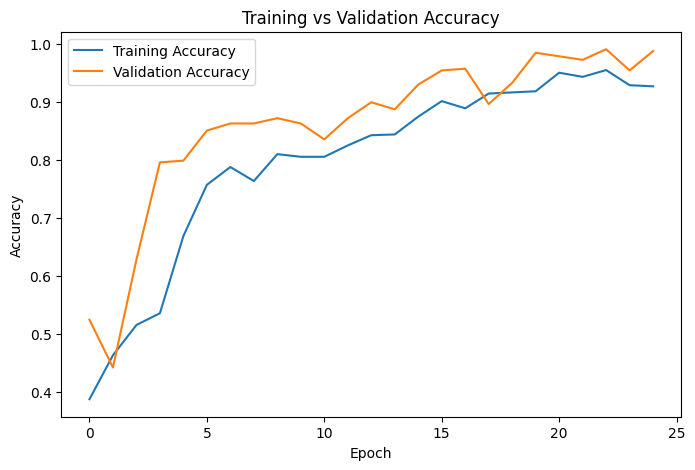

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_1.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_1.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

#### Training Vs Validation Loss Model 1

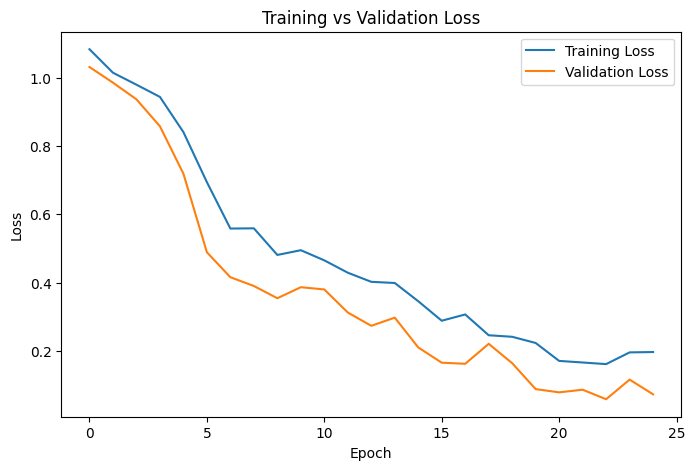

In [55]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_1.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_1.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

##### Model 1

- Model 1 is built using a **Sequential architecture**, meaning that the layers are processed in order.
- The **first convolutional layer** uses 32 filters to detect various patterns in the images.
- The **second convolutional layer** increases the number of filters to 64 to learn more complex patterns.
- The **third convolutional layer** increases the number of filters to 128 to extract more advanced features.
- **Global Average Pooling** is used to aggregate the extracted features.
- The **Dense layer** consists of 128 neurons to learn features for image classification.
- **Dropout (0.5)** randomly deactivates 50% of the neurons from the previous layer during each training step to reduce overfitting.
- Model 1 is compiled using the **Adam optimizer** with the default learning rate of 0.001.
- **Early Stopping** is applied to stop training when the monitored performance no longer improves.

##### Model 1 – Results Analysis

- Model 1 achieves an **accuracy of 0.96**, indicating strong classification performance, with a relatively low **loss of 0.13**.
- **Training vs. Validation Accuracy:** Both training and validation accuracy increase consistently. Although validation accuracy is slightly higher, this does not necessarily indicate overfitting, as data augmentation makes the training data more challenging.
- **Training vs. Validation Loss:** Both training and validation loss decrease consistently. Although validation loss slightly increases in the final epoch, a single increase is not sufficient to conclude that the model is overfitting.
- **Conclusion:** Model 1 demonstrates a **Good Fit**, with strong accuracy, low loss, and consistent training and validation performance.

# 7. Modeling 2

### Definition Model 2

In [38]:
tf.random.set_seed(42)

model_2 = Sequential([

    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(150, 150, 3)
    ),
    MaxPooling2D(2, 2),

    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D(2, 2),

    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D(2, 2),

    Flatten(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.5),

    Dense(
        3,
        activation="softmax"
    )
])

In [39]:
model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,739 (18.42 MB)

 Trainable params: 4,828,739 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

### Compile Model 2

In [40]:
model_2.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

### Callback Model 2

In [41]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

### Training Model 2

In [42]:
history_2 = model_2.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=25,
    callbacks=[early_stopping]
)

Epoch 1/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 377ms/step - accuracy: 0.5467 - loss: 0.9340 - val_accuracy: 0.8689 - val_loss: 0.4504
Epoch 2/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 34s 292ms/step - accuracy: 0.8354 - loss: 0.4532 - val_accuracy: 0.9146 - val_loss: 0.2321
Epoch 3/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 283ms/step - accuracy: 0.9288 - loss: 0.2190 - val_accuracy: 0.9817 - val_loss: 0.0555
Epoch 4/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 293ms/step - accuracy: 0.9628 - loss: 0.1315 - val_accuracy: 0.9848 - val_loss: 0.0444
Epoch 5/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 297ms/step - accuracy: 0.9549 - loss: 0.1550 - val_accuracy: 0.9817 - val_loss: 0.0551
Epoch 6/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 292ms/step - accuracy: 0.9732 - loss: 0.1029 - val_accuracy: 0.9878 - val_loss: 0.0390
Epoch 7/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 287ms/step - accuracy: 0.9595 - loss: 0.1190 - val_accuracy: 0.9939 - val_loss: 0.0270
Epoch 8/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 290ms/step - accuracy: 0.9673 - loss: 0.0921 - val_accu

### Evaluate Model 2

In [43]:
test_loss_2, test_accuracy_2 = model_2.evaluate(
    test_generator
)

print(f"Test Loss Model 2    : {test_loss_2:.4f}")
print(f"Test Accuracy Model 2 : {test_accuracy_2:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 152ms/step - accuracy: 0.9726 - loss: 0.0985
Test Loss Model 2    : 0.0985
Test Accuracy Model 2 : 0.9726


#### Training Vs Validation Accuracy Model 2

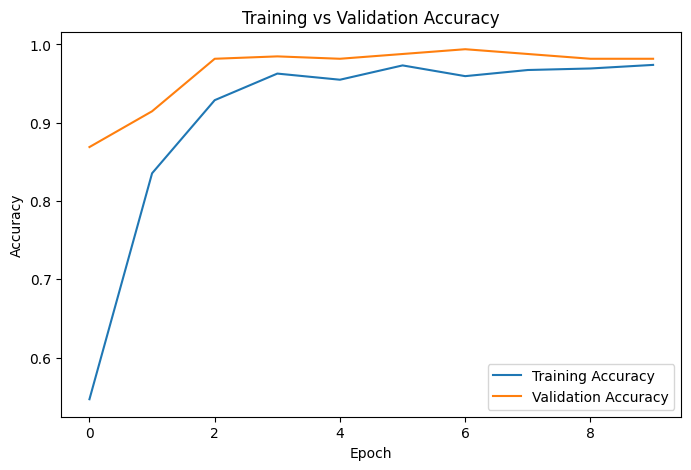

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_2.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_2.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

#### Training Vs Validation Loss Model 2

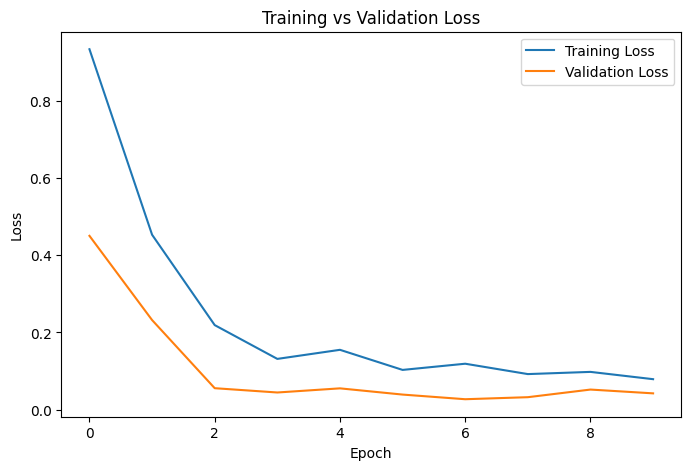

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_2.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

##### Model 2

- Model 2 is built using a **Sequential architecture**, meaning that the layers are processed in order.
- The **first convolutional layer** uses 32 filters to detect various patterns in the images.
- **Max Pooling** is applied to reduce the feature map dimensions, making computation more efficient while preserving important features.
- The **second convolutional layer** increases the number of filters to 64 to learn more complex patterns.
- The **third convolutional layer** increases the number of filters to 128 to extract more advanced features.
- **Flatten** is used to convert multidimensional feature maps into a one-dimensional vector so they can be processed by the Dense layer.
- The **Dense layer** consists of 128 neurons to learn features for image classification.
- **Dropout (0.5)** randomly deactivates 50% of the neurons from the previous layer during each training step to reduce overfitting.
- Model 2 is compiled using the **Adam optimizer** with the default learning rate of 0.001.
- **Early Stopping** is applied to stop training when the monitored performance no longer improves.

##### Model 2 – Results Analysis

- Model 2 achieves an **accuracy of 0.97**, indicating strong classification performance, with a relatively low **loss of 0.09**.
- **Training vs. Validation Accuracy:** Similar to Model 1, both training and validation accuracy increase consistently, indicating that the model is learning effectively.
- **Training vs. Validation Loss:** Both training and validation loss decrease consistently, suggesting stable learning without significant signs of overfitting.
- **Conclusion:** Model 2 demonstrates a **Good Fit**, with high accuracy, low loss, and consistent training and validation performance. It also achieves better accuracy and lower loss compared to Model 1.

# 8. Model Comparation

In [56]:
comparison = pd.DataFrame({
    "Model": [
        "Model 1 - Baseline CNN",
        "Model 2 - Improved CNN"
    ],
    "Test Accuracy": [
        test_accuracy_1,
        test_accuracy_2
    ],
    "Test Loss": [
        test_loss_1,
        test_loss_2
    ],
    "Parameters": [
        model_1.count_params(),
        model_2.count_params()
    ]
})

comparison

,Model,Test Accuracy,Test Loss,Parameters
0,Model 1 - Baseline CNN,0.963526,0.134854,101699
1,Model 2 - Improved CNN,0.972644,0.098530,4828739


##### Model Comparison Analysis

- **Model 2** shows improvements in both accuracy and loss compared to Model 1.
- **Model 1** uses Global Average Pooling with a total of **101,699 parameters**.
- **Model 2** uses Flatten followed by a Dense layer, resulting in **4,828,793 parameters**. This allows Model 2 to retain more detailed spatial information from the feature maps.
- However, the improvement in Model 2 comes with a **trade-off**, as it has significantly more parameters than Model 1, increasing computational complexity.
- Despite this trade-off, **Model 2 is selected** because it achieves better performance in terms of accuracy and loss.
- **Selected Model: Model 2**, which will be saved for further inference and deployment.


# 9. Model Saving

In [47]:
model_2.save("rps_model.keras")

print("Model successfully saved!")

Model successfully saved!


In [48]:
print(os.path.exists("rps_model.keras"))
print(f"Model size: {os.path.getsize('rps_model.keras') / (1024**2):.2f} MB")

True
Model size: 55.31 MB
